# Classificação de busca ativa por emprego

Radar de Carreira em TI. Grupo 12. CESAR School. Etapa 05. 19 de outubro de 2026.

**Objetivo:** avaliar visualmente classificadores simples de busca ativa **declarada**, com dados reais da pesquisa State of Data Brazil 2024-2025 e teste separado.

Não é previsão de desligamento futuro ou sistema para rotular empregados. O resultado serve ao estudo de avaliação de classificadores, não a decisões laborais individuais. CAGED e G12 não entram na tarefa.

## Protocolo anterior ao teste

1. Residentes no Brasil; excluir alvo ausente, sem transformar em classe 0.
2. Classe 1: busca de oportunidades dentro/fora do Brasil ou apenas fora. Classe 0: aberta a oportunidades sem busca ativa, ou sem busca e sem intenção de mudar nos próximos seis meses.
3. Separação estratificada 80/20, semente 12, antes de ajustar pré-processamento.
4. Cinco entradas nominais: senioridade declarada, formação, vínculo agrupado, modelo de trabalho e experiência em dados.
5. Comparar classe majoritária, regressão logística e árvore simples. Seleção pela maior Average Precision média em cinco folds estratificados apenas do treino. Hiperparâmetros e limiar 0,5 fixos.
6. Reajustar no treino completo e avaliar uma vez o protocolo no teste, sem reescolher modelo ou limiar.

**Vazamento:** a pergunta-alvo, cópias, entrevistas recentes, oportunidade buscada, tempo de busca e objetivo de carreira não entram como preditores. O vínculo agrupado não mantém as menções de busca do texto bruto. Ausências de senioridade podem ser estruturais, não significam Júnior.

As métricas de precisão, recall e F1 usam a classe positiva 1. AP é Average Precision, não área trapezoidal genérica. Precisão sem previsão positiva é registrada como 0 por convenção; isso é explicitado na interpretação.

In [1]:
from pathlib import Path
import sys
import inspect
from IPython.display import display, Markdown, Image, Code

local = Path.cwd()
AREA = local if (local / 'classificacao.py').exists() else local / 'inteligencia_de_carreiras/05_classificacao'
if not (AREA / 'classificacao.py').exists():
    raise FileNotFoundError('Execute na raiz do repositorio ou na etapa 05.')
sys.path.insert(0, str(AREA))
from classificacao import Classificacao, active_target, features, make_model, metricas
analise = Classificacao(AREA)
display(Markdown('Fonte preparada conferida por SHA-256; treino e teste separados antes de ajustar os modelos.'))

Fonte preparada conferida por SHA-256; treino e teste separados antes de ajustar os modelos.

## Código das regras e modelos

As funções abaixo são executadas nesta análise; o código completo está em `classificacao.py`.

In [2]:
for funcao in (active_target, features, make_model, metricas):
    display(Code(inspect.getsource(funcao), language='python'))

def active_target(series):
    if (series.notna() & ~series.isin(ACTIVE)).any():
        raise ValueError("Unmapped job-search answer; review the target before training.")
    return series.map(ACTIVE).astype("Int64")

def features(frame):
    """Select only neutral profile categories, never the raw work-status answer."""
    result = frame.loc[:, FEATURES].copy()
    for field in FEATURES:
        result[field] = result[field].astype(object).where(result[field].notna(), np.nan)
    return result

def make_model(key):
    if key == "majoritaria":
        return DummyClassifier(strategy="prior")
    if key == "logistica":
        estimator = LogisticRegression(C=1., solver="lbfgs", max_iter=2000, random_state=SEED)
    elif key == "arvore":
        estimator = DecisionTreeClassifier(max_depth=4, min_samples_leaf=40, random_state=SEED)
    else:
        raise ValueError(key)
    return Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="Nao informado", keep_empty_features=True)),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ("modelo", estimator),
    ])

def metricas(y, probabilities, threshold=THRESHOLD):
    y = np.asarray(y)
    p = np.asarray(probabilities, dtype=float)
    if not len(y) or len(y) != len(p) or not set(y).issubset({0, 1}):
        raise ValueError("Invalid binary targets")
    y = y.astype(int)
    predicted = labels(p, threshold)
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {"n": len(y), "n_ativos": int(y.sum()), "n_previstos_ativos": int(predicted.sum()),
            "limiar": threshold, "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
            "acuracia": float(accuracy_score(y, predicted)),
            "precisao": float(precision_score(y, predicted, zero_division=0)),
            "recall": float(recall_score(y, predicted, zero_division=0)),
            "f1": float(f1_score(y, predicted, zero_division=0)),
            "roc_auc": float(roc_auc_score(y, p)) if both else None,
            "average_precision": float(average_precision_score(y, p)) if both else None,
            "brier": float(brier_score_loss(y, p))}

## C0. Alvo real, elegibilidade e particoes

### Particoes classes

,particao,n,sem_busca_ativa,busca_ativa,proporcao_ativa
0,Treino (80%),3787,2483,1304,0.3443
1,Teste (20%),947,621,326,0.3442


### Cobertura entradas

,variavel,ausentes_treino,ausentes_teste,tratamento
0,senioridade_declarada,824,187,categoria explicita; sem inferir senioridade
1,nivel_ensino,0,0,categoria explicita; sem inferir senioridade
2,vinculo_grupo,0,0,categoria explicita; sem inferir senioridade
3,modelo_trabalho_declarado,0,0,categoria explicita; sem inferir senioridade
4,experiencia_dados_faixa,0,0,categoria explicita; sem inferir senioridade


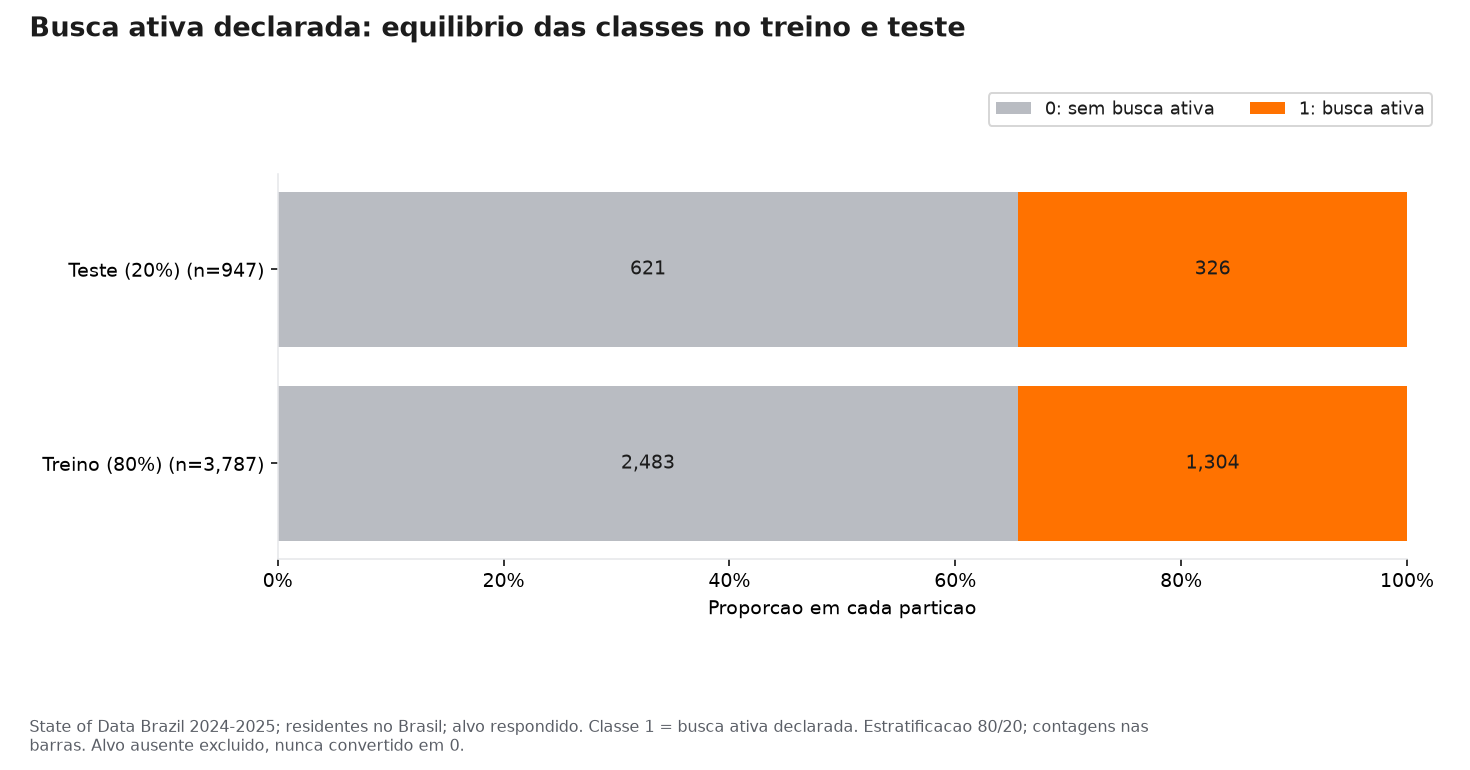

### Interpretacao

Dos 5,076 residentes no Brasil, 342 nao tem alvo respondido e nao recebem classe 0. Restam 4,734 respostas, 1,630 positivas (34.4%). A separacao estratificada, semente 12, reserva 947 respostas para teste e 3787 para treino. A classe 0 inclui pessoas abertas a oportunidades, mas que nao declaram busca ativa. O alvo e intencao contemporanea, nao mudanca de emprego futura. As ausencias se concentram em ramos do questionario; os elegiveis nao representam todos os desempregados ou toda a populacao de TI. Senioridade ausente nao vira Junior. Vinculo agrupado remove mencoes de busca presentes no texto bruto.

In [3]:
resultado = analise.run('C0')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## C1. Validacao apenas no treino e modelos simples

In [4]:
resultado = analise.run('C1')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

### Validacao folds

,modelo,fold,n,n_ativos,n_previstos_ativos,limiar,tn,fp,fn,tp,acuracia,precisao,recall,f1,roc_auc,average_precision,brier
0,majoritaria,1,758,261,0,0.5,497,0,261,0,0.6557,0.0000,0.0000,0.0000,0.5000,0.3443,0.2258
1,majoritaria,2,758,261,0,0.5,497,0,261,0,0.6557,0.0000,0.0000,0.0000,0.5000,0.3443,0.2258
2,majoritaria,3,757,261,0,0.5,496,0,261,0,0.6552,0.0000,0.0000,0.0000,0.5000,0.3448,0.2259
3,majoritaria,4,757,261,0,0.5,496,0,261,0,0.6552,0.0000,0.0000,0.0000,0.5000,0.3448,0.2259
4,majoritaria,5,757,260,0,0.5,497,0,260,0,0.6565,0.0000,0.0000,0.0000,0.5000,0.3435,0.2255
5,logistica,1,758,261,56,0.5,471,26,231,30,0.6609,0.5357,0.1149,0.1893,0.6076,0.4411,0.2198
6,logistica,2,758,261,58,0.5,472,25,228,33,0.6662,0.5690,0.1264,0.2069,0.6200,0.4590,0.2170
7,logistica,3,757,261,40,0.5,478,18,239,22,0.6605,0.5500,0.0843,0.1462,0.6096,0.4417,0.2185
8,logistica,4,757,261,59,0.5,469,27,229,32,0.6618,0.5424,0.1226,0.2000,0.6165,0.4665,0.2169
9,logistica,5,757,260,46,0.5,478,19,233,27,0.6671,0.5870,0.1038,0.1765,0.6096,0.4314,0.2188


### Selecao treino

,modelo,ordem,ap_media,ap_desvio_folds,f1_medio_limiar_05,roc_auc_media,n_folds
0,majoritaria,0,0.3443,0.0005,0.0000,0.5000,5
1,logistica,1,0.4479,0.0144,0.1838,0.6127,5
2,arvore,2,0.4053,0.0082,0.0889,0.5831,5


### Metricas teste

,modelo,n,n_ativos,n_previstos_ativos,limiar,tn,fp,fn,tp,acuracia,precisao,recall,f1,roc_auc,average_precision,brier
0,majoritaria,947,326,0,0.5,621,0,326,0,0.6558,0.0000,0.0000,0.0000,0.5000,0.3442,0.2257
1,logistica,947,326,79,0.5,584,37,284,42,0.6610,0.5316,0.1288,0.2074,0.6013,0.4351,0.2197
2,arvore,947,326,33,0.5,601,20,313,13,0.6484,0.3939,0.0399,0.0724,0.5792,0.3980,0.2232


### Interpretacao

A escolha feita somente no treino foi **Regressao logistica**, com Average Precision media 0.448 em cinco folds (desvio entre folds 0.014, nao intervalo de confianca). Cada fold ajusta imputacao, categorias e modelo apenas nos seus dados de treino. A referencia aprende a proporcao das classes no treino e decide a classe majoritaria. Os tres modelos sao depois reajustados nos 80% e avaliados nos mesmos 20% reservados. C, profundidade e tamanho minimo de folha sao fixos; limiar 0,5 definido previamente, sem otimizacao. O teste nao decide modelo, hiperparametros ou limiar. As probabilidades OOF sao usadas apenas para diagnostico interno.

## C2. Acuracia, precisao, recall e F1

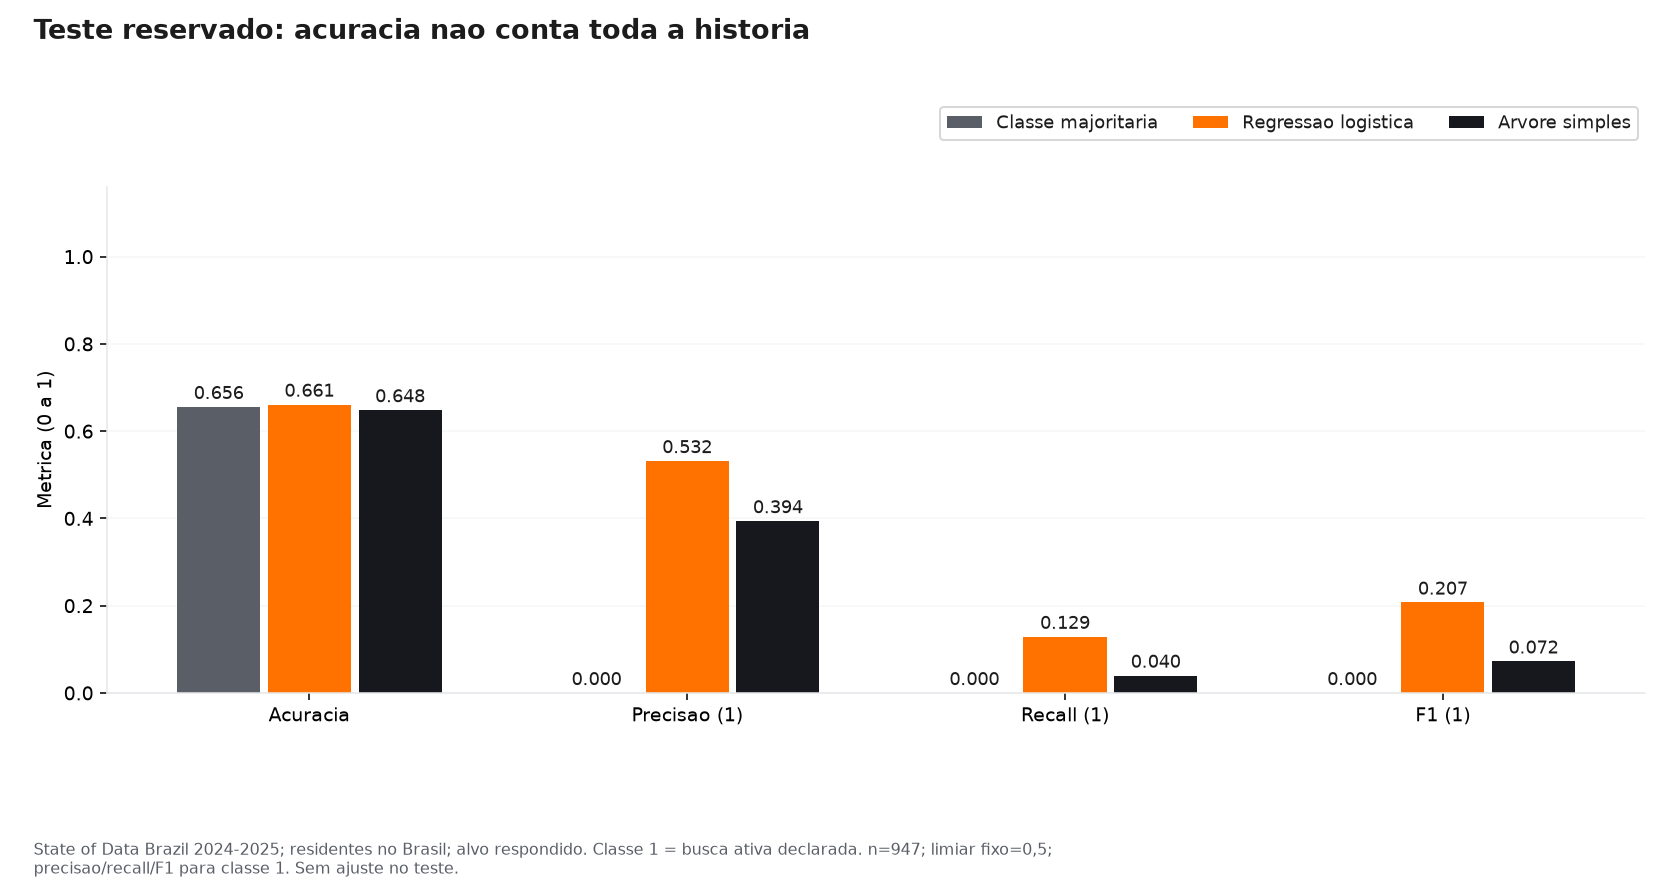

### Interpretacao

A referencia acerta 65.6% simplesmente escolhendo a classe 0, mas nao identifica nenhuma busca ativa: recall e F1 iguais a zero. Por isso acuracia sozinha seria enganosa. O modelo escolhido tem acuracia 0.661, precisao 0.532, recall 0.129 e F1 0.207 no limiar 0,5. Precisao descreve a fracao correta entre positivos previstos; recall, a fracao de buscas ativas identificadas. Precisao sem positivos previstos e registrada como 0 por convencao zero_division=0, nao como evidencia de taxa populacional. F1 combina precisao e recall, mas ignora os verdadeiros negativos. O escolhido deixa de identificar 87.1% dos positivos; este desempenho e limitado e nao valida uma ferramenta de deteccao individual. O limiar nao foi alterado para melhorar os resultados do teste.

In [5]:
resultado = analise.run('C2')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## C3. Matrizes de confusao e tipos de erro

### Matrizes confusao

,modelo,classe_observada,classe_prevista,n,proporcao_na_classe_observada
0,majoritaria,0,0,621,1.0000
1,majoritaria,0,1,0,0.0000
2,majoritaria,1,0,326,1.0000
3,majoritaria,1,1,0,0.0000
4,logistica,0,0,584,0.9404
5,logistica,0,1,37,0.0596
6,logistica,1,0,284,0.8712
7,logistica,1,1,42,0.1288
8,arvore,0,0,601,0.9678
9,arvore,0,1,20,0.0322


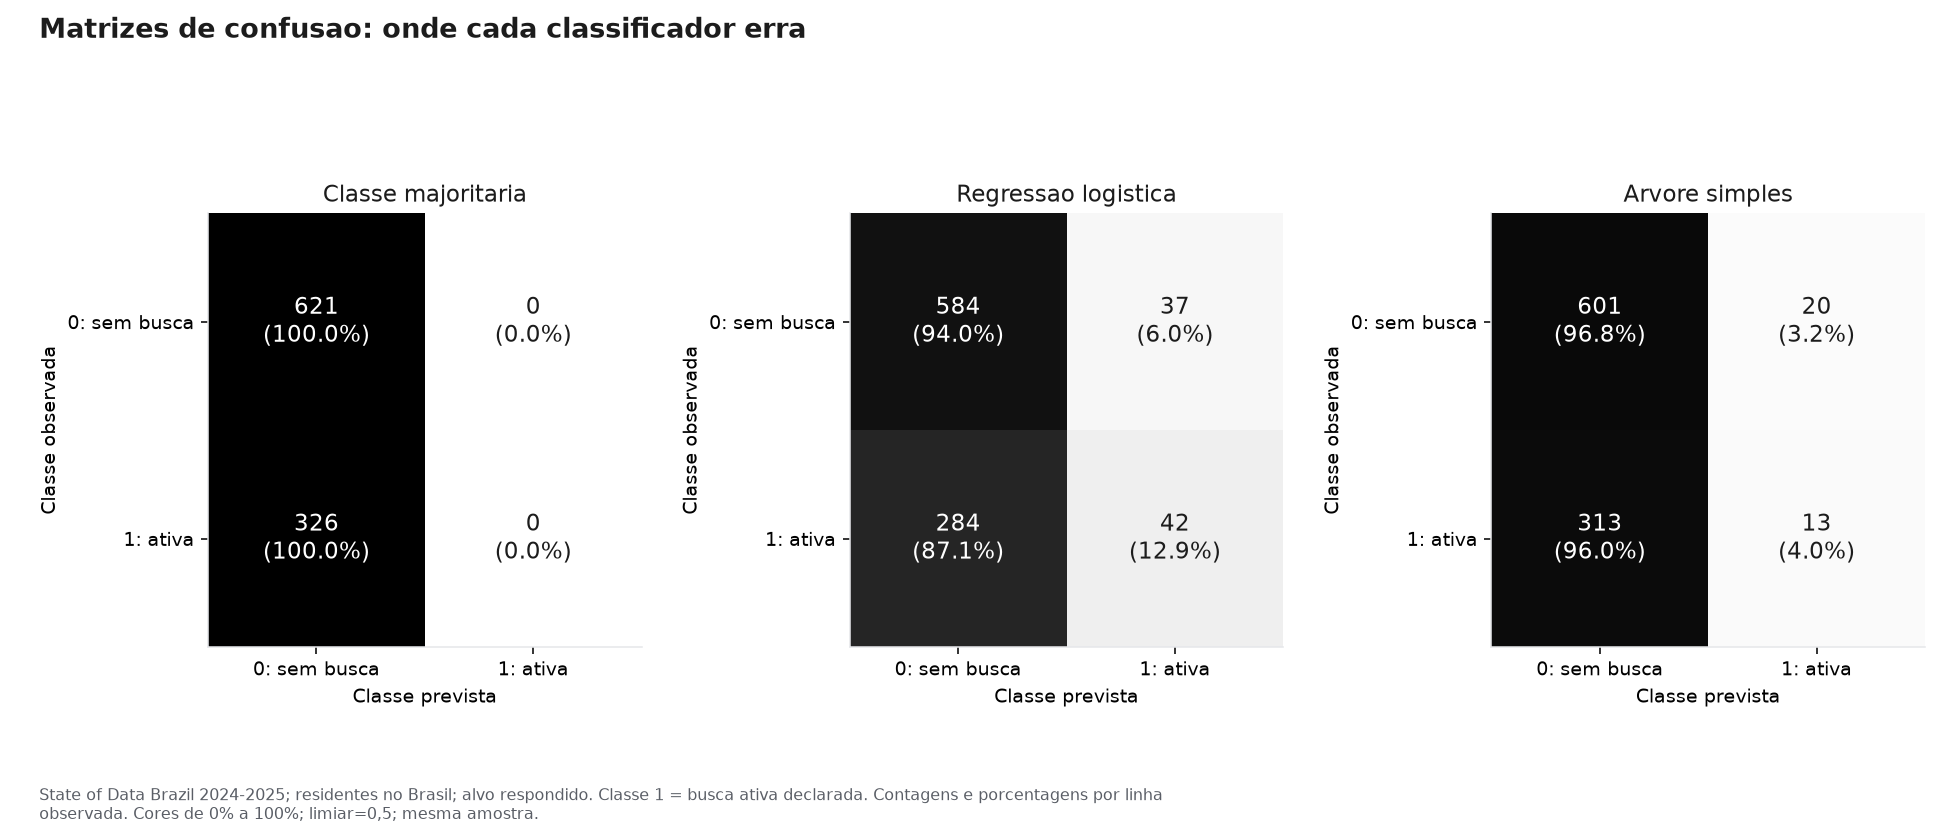

### Interpretacao

Para Regressao logistica, ha 42 verdadeiros positivos, 284 falsos negativos, 37 falsos positivos e 584 verdadeiros negativos. Um falso negativo e uma pessoa que declara busca ativa e recebe classe 0; um falso positivo recebe classe 1 sem declarar busca ativa. As porcentagens usam a classe observada como denominador e cada linha soma 100%; as contagens preservam o tamanho real das classes. Esses erros impedem usar a classificacao para rotular empregados ou orientar decisoes de contratacao, desligamento ou vigilancia.

In [6]:
resultado = analise.run('C3')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## C4. Curvas ROC e ROC-AUC

### Curvas roc

,modelo,taxa_falso_positivo,taxa_verdadeiro_positivo,limiar
0,majoritaria,0.0000,0.0000,NaN
1,majoritaria,1.0000,1.0000,0.3443
2,logistica,0.0000,0.0000,NaN
3,logistica,0.0016,0.0000,0.6942
4,logistica,0.0032,0.0000,0.6705
5,logistica,0.0032,0.0031,0.6689
6,logistica,0.0032,0.0092,0.6579
7,logistica,0.0081,0.0123,0.6541
8,logistica,0.0097,0.0123,0.6438
9,logistica,0.0097,0.0153,0.6396


Exibidas 18 de 320 linhas; CSV completo em resultados/tabelas.

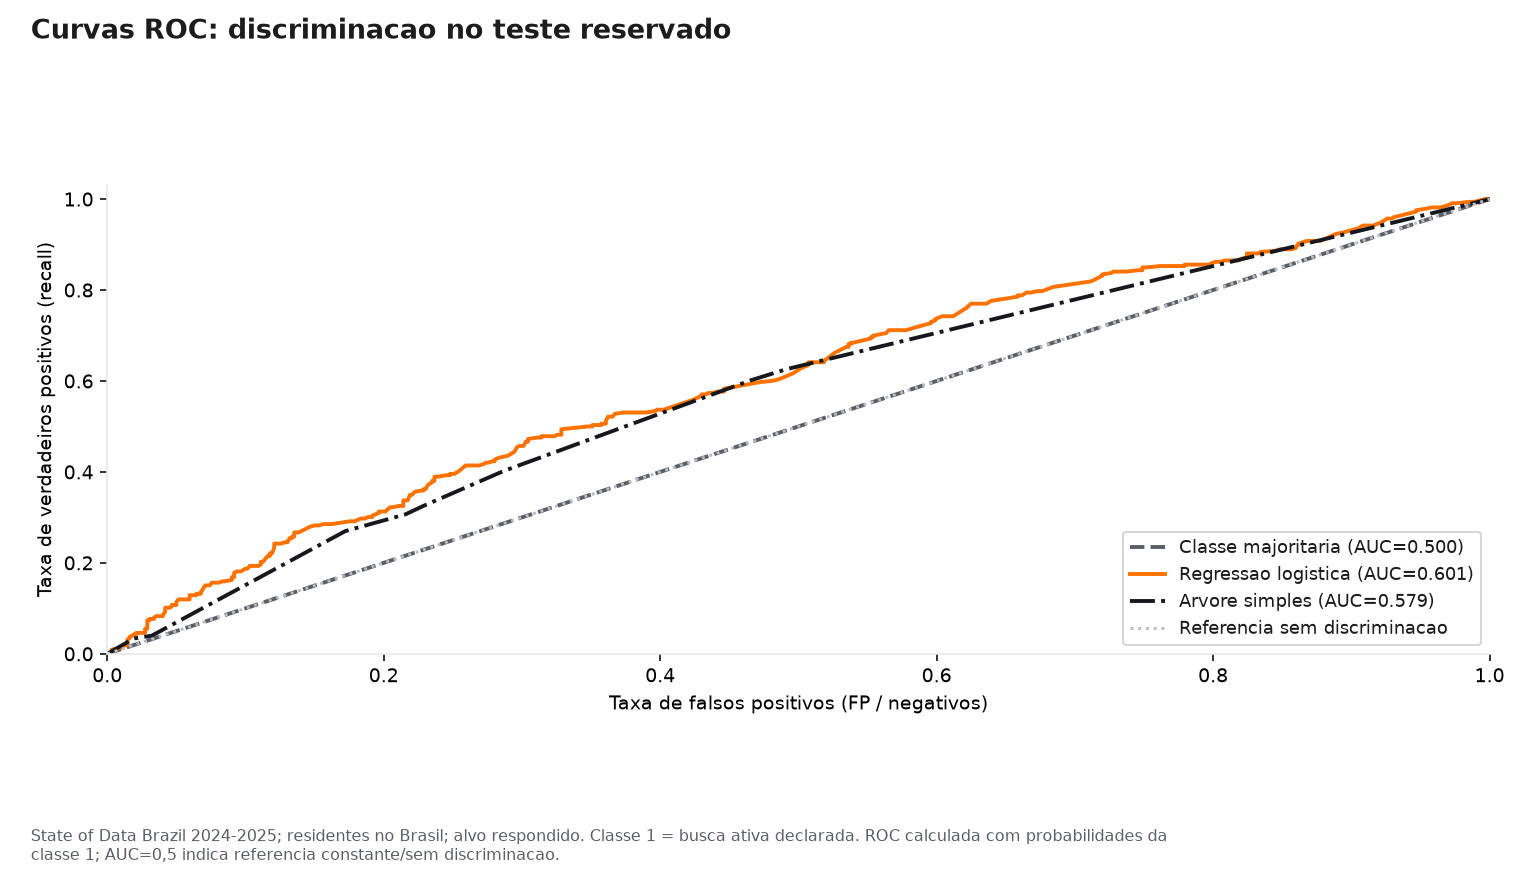

### Interpretacao

O modelo previamente escolhido tem ROC-AUC 0.601. A curva usa escores/probabilidades, nao somente as classes do limiar 0,5; mostra o compromisso entre falsos positivos e recall. A referencia constante tem AUC 0,5. AUC e capacidade de ordenacao, nao acuracia, probabilidade de acerto individual ou prova de causalidade. A classe positiva e 1 em todos os calculos. O teste e uma avaliacao da mesma pesquisa, nao validacao temporal externa.

In [7]:
resultado = analise.run('C4')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## C5. Curvas precision-recall e Average Precision

### Curvas precision recall

,modelo,recall,precisao,limiar
0,majoritaria,1.0000,0.3442,0.3443
1,majoritaria,0.0000,1.0000,NaN
2,logistica,1.0000,0.3442,0.1511
3,logistica,1.0000,0.3450,0.1703
4,logistica,0.9939,0.3454,0.1724
5,logistica,0.9939,0.3462,0.1744
6,logistica,0.9908,0.3477,0.1749
7,logistica,0.9908,0.3484,0.1791
8,logistica,0.9877,0.3481,0.1841
9,logistica,0.9847,0.3482,0.1845


Exibidas 18 de 390 linhas; CSV completo em resultados/tabelas.

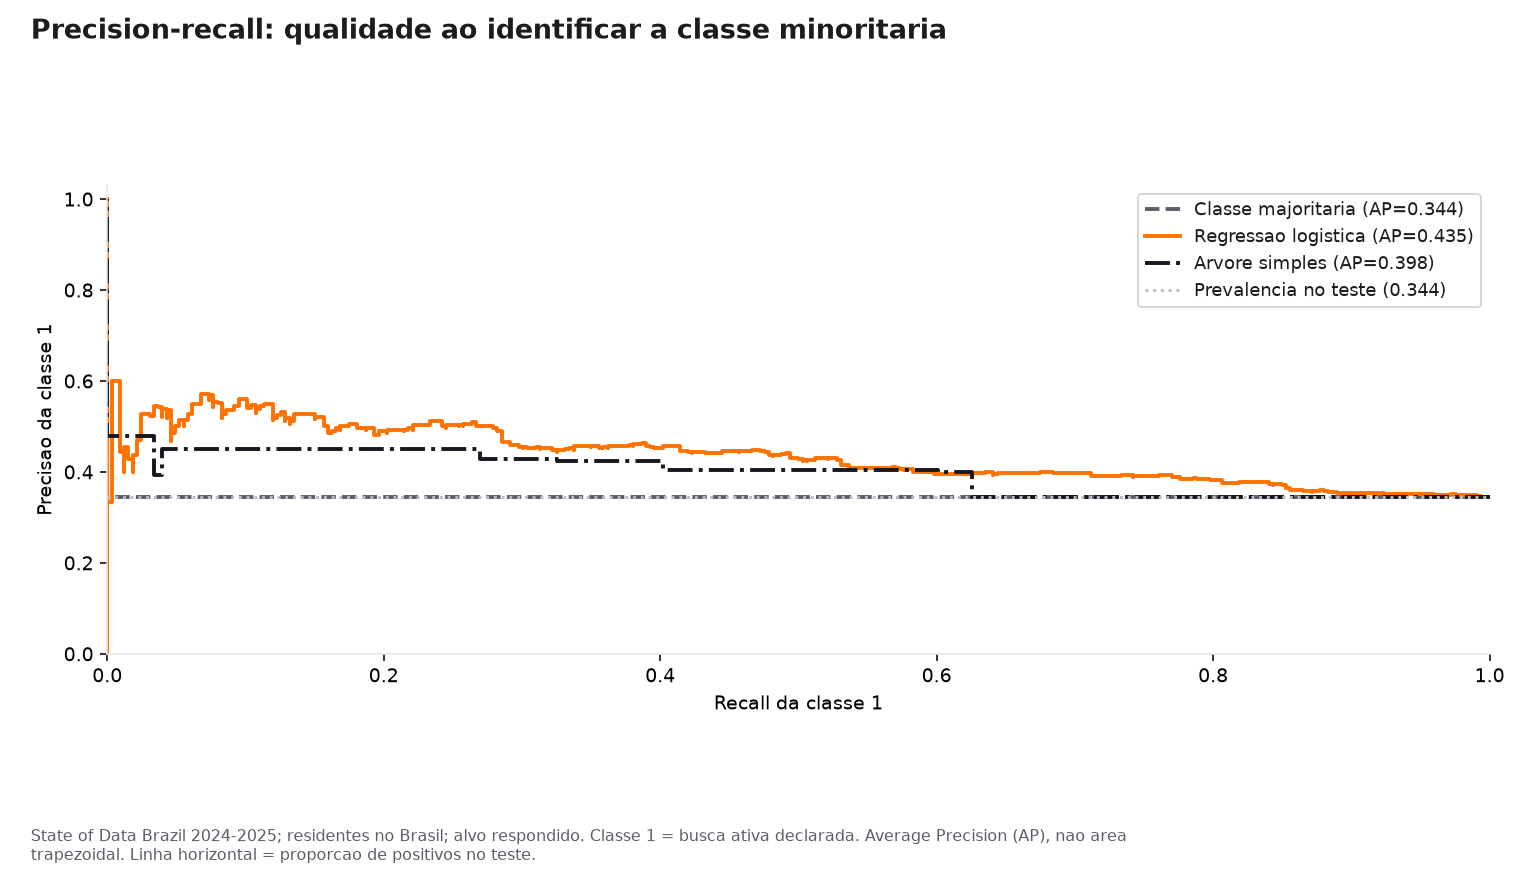

### Interpretacao

Average Precision (AP) do escolhido: 0.435; referencia constante: prevalencia de 0.344. AP resume a curva ponderando os incrementos de recall e nao e a area trapezoidal generica sob a PR. A leitura considera que buscas ativas sao a classe minoritaria. Ganhar recall costuma incluir mais falsos positivos. O ultimo ponto convencional da curva tem precisao 1 e recall 0, sem observacoes previstas positivas; nao prova um classificador perfeito. A precisao e a AP dependem da prevalencia, portanto nao podem ser transferidas diretamente para outra populacao.

In [8]:
resultado = analise.run('C5')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## C6. Efeito do limiar: diagnostico interno do treino

### Limiares oof treino

,n,n_ativos,n_previstos_ativos,limiar,tn,fp,fn,tp,acuracia,precisao,recall,f1,roc_auc,average_precision,brier
0,3787,1304,3787,0.05,0,2483,0,1304,0.3443,0.3443,1.0000,0.5123,0.6116,0.4451,0.2182
1,3787,1304,3787,0.10,0,2483,0,1304,0.3443,0.3443,1.0000,0.5123,0.6116,0.4451,0.2182
2,3787,1304,3786,0.15,1,2482,0,1304,0.3446,0.3444,1.0000,0.5124,0.6116,0.4451,0.2182
3,3787,1304,3595,0.20,153,2330,39,1265,0.3744,0.3519,0.9701,0.5164,0.6116,0.4451,0.2182
4,3787,1304,3152,0.25,488,1995,147,1157,0.4344,0.3671,0.8873,0.5193,0.6116,0.4451,0.2182
5,3787,1304,2461,0.30,980,1503,346,958,0.5118,0.3893,0.7347,0.5089,0.6116,0.4451,0.2182
6,3787,1304,1447,0.35,1672,811,668,636,0.6095,0.4395,0.4877,0.4624,0.6116,0.4451,0.2182
7,3787,1304,1013,0.40,1948,535,826,478,0.6406,0.4719,0.3666,0.4126,0.6116,0.4451,0.2182
8,3787,1304,532,0.45,2223,260,1032,272,0.6588,0.5113,0.2086,0.2963,0.6116,0.4451,0.2182
9,3787,1304,259,0.50,2368,115,1160,144,0.6633,0.5560,0.1104,0.1843,0.6116,0.4451,0.2182


Exibidas 18 de 19 linhas; CSV completo em resultados/tabelas.

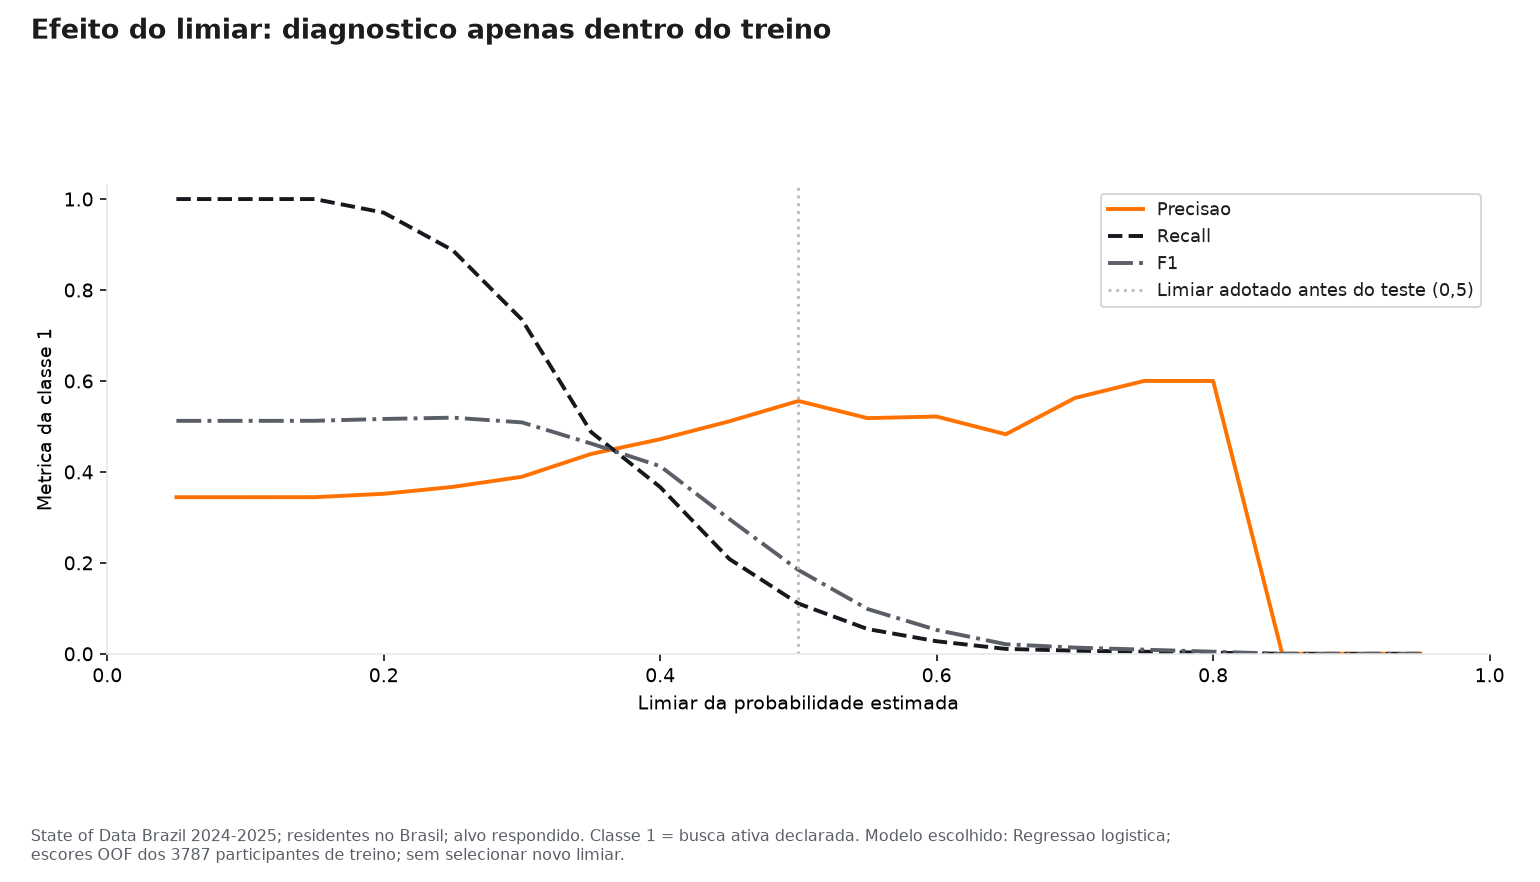

### Interpretacao

Esta curva usa somente previsoes out-of-fold do treino: cada linha foi prevista por um pipeline que nao a usou no ajuste daquele fold. O modelo foi selecionado com os mesmos folds, portanto a curva e um diagnostico interno e pode ser otimista. Limiar 0,5 permanece fixo; nenhum ponto foi escolhido por maximizar F1 nesta curva ou no teste. Reduzir o limiar tende a ampliar recall e alertas falsos; aumentar pode deixar mais buscas ativas sem identificacao. Uma alteracao futura exige objetivo/custos definidos e nova validacao, nao reutilizar este teste como treino.

In [9]:
resultado = analise.run('C6')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## C7. Calibracao descritiva dos escores

### Calibracao faixas

,faixa,n,probabilidade_media,proporcao_ativa,suficiente
0,"(-0.001, 0.2]",41,0.1803,0.1951,True
1,"(0.2, 0.4]",645,0.3042,0.3101,True
2,"(0.4, 0.6]",239,0.4665,0.4435,True
3,"(0.6, 0.8]",22,NaN,NaN,False


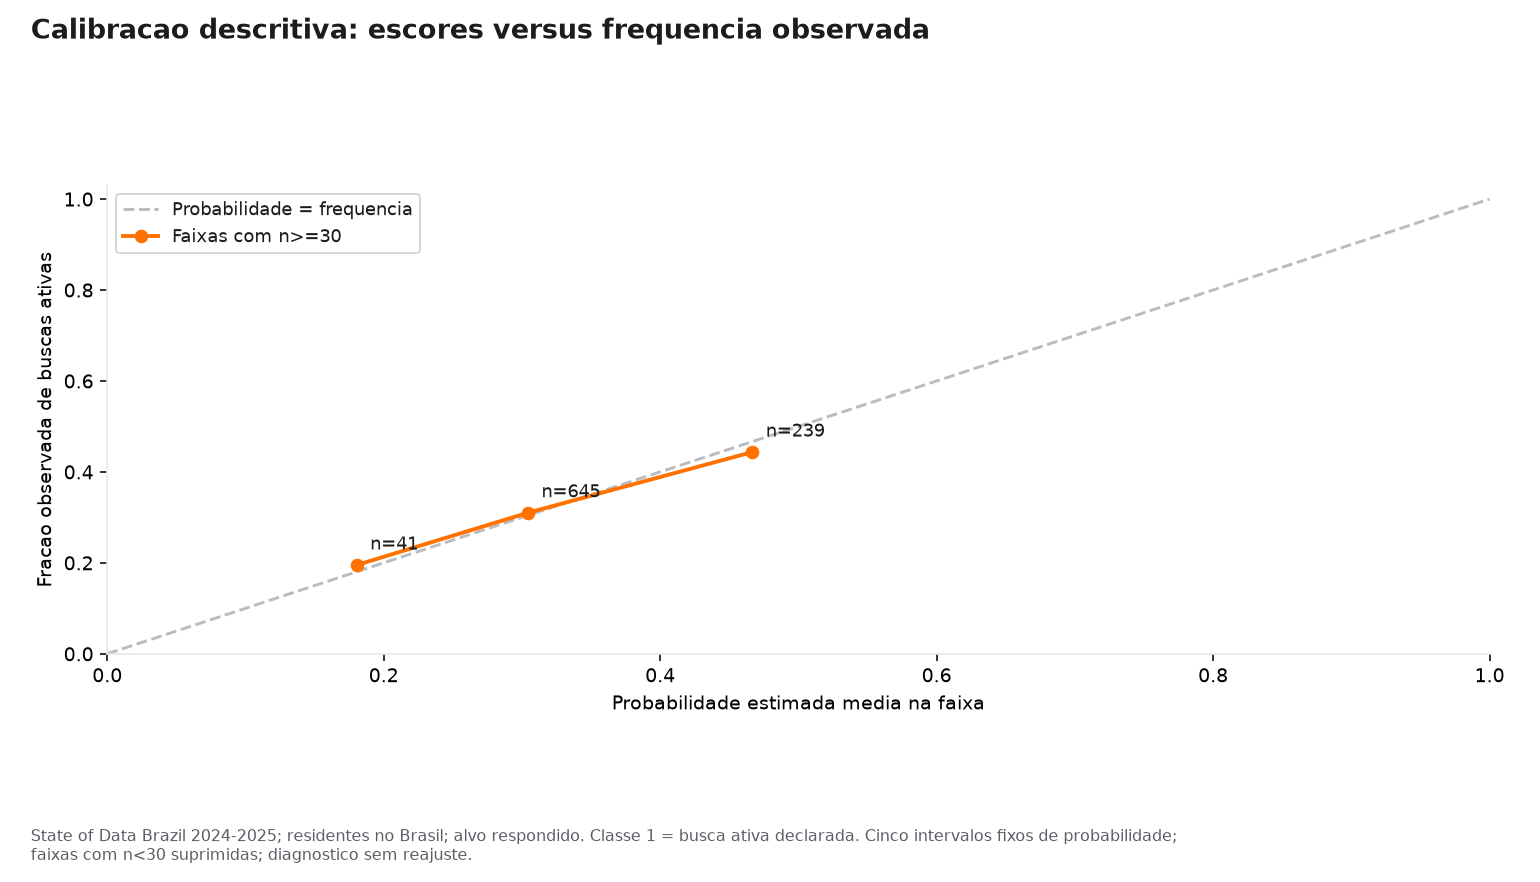

### Interpretacao

Brier score do escolhido: 0.220 (menor e melhor). O grafico agrupa probabilidades do teste em cinco intervalos fixos e mostra apenas faixas com n>=30; nao recalibra o modelo. Distancia da diagonal representa diferenca entre escore medio e frequencia observada. As probabilidades nao foram calibradas externamente e nao sao riscos pessoais comprovados de demissao ou mudanca futura. Discriminacao e calibracao sao conceitos distintos.

In [10]:
resultado = analise.run('C7')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

## C8. Cobertura, elegibilidade e limites por recorte

In [11]:
resultado = analise.run('C8')
for nome, tabela in resultado['tabelas'].items():
    display(Markdown('### ' + nome.replace('_', ' ').capitalize()))
    display(tabela.round(4).head(18))
    if len(tabela) > 18:
        display(Markdown(f'Exibidas 18 de {len(tabela)} linhas; CSV completo em resultados/tabelas.'))
for grafico in resultado['graficos']:
    display(Image(filename=str(grafico)))
display(Markdown('### Interpretacao' + chr(10)*2 + resultado['interpretacao']))

### Cobertura recortes

,dimensao,grupo,n,suficiente,n_ativos,n_previstos_ativos,limiar,tn,fp,fn,tp,acuracia,precisao,recall,f1,roc_auc,average_precision,brier
0,regiao,Brasil,947,True,326.0,79.0,0.5,584.0,37.0,284.0,42.0,0.6610,0.5316,0.1288,0.2074,0.6013,0.4351,0.2197
1,regiao,Nordeste,89,True,36.0,8.0,0.5,51.0,2.0,30.0,6.0,0.6404,0.7500,0.1667,0.2727,0.5917,0.5739,0.2340
2,regiao,Pernambuco,17,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,senioridade,Junior,180,True,70.0,33.0,0.5,93.0,17.0,54.0,16.0,0.6056,0.4848,0.2286,0.3107,0.5878,0.4464,0.2360
4,senioridade,Nao informado,187,True,43.0,11.0,0.5,136.0,8.0,40.0,3.0,0.7433,0.2727,0.0698,0.1111,0.5615,0.2784,0.1839
5,senioridade,Pleno,276,True,110.0,27.0,0.5,156.0,10.0,93.0,17.0,0.6268,0.6296,0.1545,0.2482,0.5853,0.5209,0.2315
6,senioridade,Senior,304,True,103.0,8.0,0.5,199.0,2.0,97.0,6.0,0.6743,0.7500,0.0583,0.1081,0.5590,0.4227,0.2214


### Categorias novas

,variavel,n_categoria_nova,n_teste
0,senioridade_declarada,0,947
1,nivel_ensino,0,947
2,vinculo_grupo,0,947
3,modelo_trabalho_declarado,0,947
4,experiencia_dados_faixa,0,947


### Ausencia alvo por vinculo

,vinculo_grupo,n,alvo_ausente
0,Academico ou pesquisador,55,55
1,CLT,3749,0
2,Desempregado,210,200
3,Estagio,185,0
4,Estudante,87,87
5,Freelancer,35,0
6,Nao informado,16,0
7,PJ ou empreendedor,486,0
8,Servidor publico,121,0
9,Trabalho internacional,132,0


### Interpretacao

Pernambuco tem n=17 no teste; n<30, portanto suas metricas foram suprimidas. Brasil/NE/PE sao recortes aninhados, nao somaveis. A tabela por vinculo evidencia quem ficou sem alvo, reforcando o vies de elegibilidade do questionario; a exclusao nao equivale a nao buscar emprego. Nulos de senioridade podem vir de ramificacoes do formulario, inclusive gestao: nao representam senioridade baixa. Categorias novas do teste sao ignoradas pelo encoder sem ajustar novamente. Nao foi feita auditoria de equidade, validacao com outra pesquisa ou avaliacao temporal externa. Nao aplicar estes modelos para rotular pessoas em decisoes laborais.

## Conclusão e uso responsável

A síntese é gerada a partir dos resultados, incluindo métricas desfavoráveis. A pesquisa é voluntária e o teste pertence à mesma coleta; não houve validação externa ou temporal. O alvo ausente está concentrado em ramos do questionário, o que limita a população elegível.

Saídas versionáveis são agregadas. IDs e probabilidades por participante ficam em `resultados_locais/`, ignorada pelo Git. Não usar o classificador para monitorar trabalhadores ou decidir contratação/desligamento. Nada foi integrado automaticamente ao dashboard ou enviado ao GitHub.

In [12]:
analise.summary()
display(Markdown((AREA / 'sintese_achados.md').read_text(encoding='utf-8')))
display(Markdown('Analise concluida. Auditoria e tabelas completas em resultados/.'))

# Sintese da classificacao de busca ativa

Etapa 05. State of Data Brazil 2024-2025; avaliacao de intencao declarada, nao de desligamento futuro.

## C0

Dos 5,076 residentes no Brasil, 342 nao tem alvo respondido e nao recebem classe 0. Restam 4,734 respostas, 1,630 positivas (34.4%). A separacao estratificada, semente 12, reserva 947 respostas para teste e 3787 para treino. A classe 0 inclui pessoas abertas a oportunidades, mas que nao declaram busca ativa. O alvo e intencao contemporanea, nao mudanca de emprego futura. As ausencias se concentram em ramos do questionario; os elegiveis nao representam todos os desempregados ou toda a populacao de TI. Senioridade ausente nao vira Junior. Vinculo agrupado remove mencoes de busca presentes no texto bruto.

## C1

A escolha feita somente no treino foi **Regressao logistica**, com Average Precision media 0.448 em cinco folds (desvio entre folds 0.014, nao intervalo de confianca). Cada fold ajusta imputacao, categorias e modelo apenas nos seus dados de treino. A referencia aprende a proporcao das classes no treino e decide a classe majoritaria. Os tres modelos sao depois reajustados nos 80% e avaliados nos mesmos 20% reservados. C, profundidade e tamanho minimo de folha sao fixos; limiar 0,5 definido previamente, sem otimizacao. O teste nao decide modelo, hiperparametros ou limiar. As probabilidades OOF sao usadas apenas para diagnostico interno.

## C2

A referencia acerta 65.6% simplesmente escolhendo a classe 0, mas nao identifica nenhuma busca ativa: recall e F1 iguais a zero. Por isso acuracia sozinha seria enganosa. O modelo escolhido tem acuracia 0.661, precisao 0.532, recall 0.129 e F1 0.207 no limiar 0,5. Precisao descreve a fracao correta entre positivos previstos; recall, a fracao de buscas ativas identificadas. Precisao sem positivos previstos e registrada como 0 por convencao zero_division=0, nao como evidencia de taxa populacional. F1 combina precisao e recall, mas ignora os verdadeiros negativos. O escolhido deixa de identificar 87.1% dos positivos; este desempenho e limitado e nao valida uma ferramenta de deteccao individual. O limiar nao foi alterado para melhorar os resultados do teste.

## C3

Para Regressao logistica, ha 42 verdadeiros positivos, 284 falsos negativos, 37 falsos positivos e 584 verdadeiros negativos. Um falso negativo e uma pessoa que declara busca ativa e recebe classe 0; um falso positivo recebe classe 1 sem declarar busca ativa. As porcentagens usam a classe observada como denominador e cada linha soma 100%; as contagens preservam o tamanho real das classes. Esses erros impedem usar a classificacao para rotular empregados ou orientar decisoes de contratacao, desligamento ou vigilancia.

## C4

O modelo previamente escolhido tem ROC-AUC 0.601. A curva usa escores/probabilidades, nao somente as classes do limiar 0,5; mostra o compromisso entre falsos positivos e recall. A referencia constante tem AUC 0,5. AUC e capacidade de ordenacao, nao acuracia, probabilidade de acerto individual ou prova de causalidade. A classe positiva e 1 em todos os calculos. O teste e uma avaliacao da mesma pesquisa, nao validacao temporal externa.

## C5

Average Precision (AP) do escolhido: 0.435; referencia constante: prevalencia de 0.344. AP resume a curva ponderando os incrementos de recall e nao e a area trapezoidal generica sob a PR. A leitura considera que buscas ativas sao a classe minoritaria. Ganhar recall costuma incluir mais falsos positivos. O ultimo ponto convencional da curva tem precisao 1 e recall 0, sem observacoes previstas positivas; nao prova um classificador perfeito. A precisao e a AP dependem da prevalencia, portanto nao podem ser transferidas diretamente para outra populacao.

## C6

Esta curva usa somente previsoes out-of-fold do treino: cada linha foi prevista por um pipeline que nao a usou no ajuste daquele fold. O modelo foi selecionado com os mesmos folds, portanto a curva e um diagnostico interno e pode ser otimista. Limiar 0,5 permanece fixo; nenhum ponto foi escolhido por maximizar F1 nesta curva ou no teste. Reduzir o limiar tende a ampliar recall e alertas falsos; aumentar pode deixar mais buscas ativas sem identificacao. Uma alteracao futura exige objetivo/custos definidos e nova validacao, nao reutilizar este teste como treino.

## C7

Brier score do escolhido: 0.220 (menor e melhor). O grafico agrupa probabilidades do teste em cinco intervalos fixos e mostra apenas faixas com n>=30; nao recalibra o modelo. Distancia da diagonal representa diferenca entre escore medio e frequencia observada. As probabilidades nao foram calibradas externamente e nao sao riscos pessoais comprovados de demissao ou mudanca futura. Discriminacao e calibracao sao conceitos distintos.

## C8

Pernambuco tem n=17 no teste; n<30, portanto suas metricas foram suprimidas. Brasil/NE/PE sao recortes aninhados, nao somaveis. A tabela por vinculo evidencia quem ficou sem alvo, reforcando o vies de elegibilidade do questionario; a exclusao nao equivale a nao buscar emprego. Nulos de senioridade podem vir de ramificacoes do formulario, inclusive gestao: nao representam senioridade baixa. Categorias novas do teste sao ignoradas pelo encoder sem ajustar novamente. Nao foi feita auditoria de equidade, validacao com outra pesquisa ou avaliacao temporal externa. Nao aplicar estes modelos para rotular pessoas em decisoes laborais.

## Uso e limites

Estudo exploratorio com pesquisa voluntaria e um teste estratificado da mesma coleta. Nao representa todos os profissionais de TI, nao identifica causalidade e nao valida uso em contratacao, demissao, monitoramento de empregados ou aconselhamento individual automatizado. Nenhuma fonte CAGED ou G12 foi adicionada. Probabilidades por participante ficam locais; resultados versionaveis sao agregados. A etapa 06 ainda exige integracao, narrativa, usabilidade e revisao de privacidade; nenhum classificador foi integrado automaticamente ao aplicativo.


Analise concluida. Auditoria e tabelas completas em resultados/.